# 1. Data Understanding

This notebook focuses on understanding the  dataset before performing any data cleaning or transformation.

The main objectives are:

- Understand the dataset structure
- Identify the available variables
- Inspect data types
- Analyze missing values
- Check for duplicated records
- Explore basic statistics
- Identify potential data quality issues

In [1]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset

df = pd.read_csv("../data/hmeq.csv")

In [3]:
# Print the first few rows of the dataset to understand its structure and contents
df.head(15)

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN
5,1,1700,30548.0,40320.0,HomeImp,Other,9.0,0.0,0.0,101.466002,1.0,8.0,37.113614
6,1,1800,48649.0,57037.0,HomeImp,Other,5.0,3.0,2.0,77.100000,1.0,17.0,NaN
7,1,1800,28502.0,43034.0,HomeImp,Other,11.0,0.0,0.0,88.766030,0.0,8.0,36.884894
8,1,2000,32700.0,46740.0,HomeImp,Other,3.0,0.0,2.0,216.933333,1.0,12.0,NaN
9,1,2000,NaN,62250.0,HomeImp,Sales,16.0,0.0,0.0,115.800000,0.0,13.0,NaN


In [4]:
# Check for size of the dataset and get a summary of the dataset's structure, including the number of rows, columns, and data types of each column.
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

data_overview = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.values,
    "missing_values": df.isna().sum().values,
    "missing_%": (df.isna().mean() * 100).round(2).values,
    "unique_values": df.nunique().values
})

data_overview

Rows: 5,960
Columns: 13


,column,dtype,missing_values,missing_%,unique_values
0,BAD,int64,0,0.00,2
1,LOAN,int64,0,0.00,540
2,MORTDUE,float64,518,8.69,5053
3,VALUE,float64,112,1.88,5381
4,REASON,str,252,4.23,2
5,JOB,str,279,4.68,6
6,YOJ,float64,515,8.64,99
7,DEROG,float64,708,11.88,11
8,DELINQ,float64,580,9.73,14
9,CLAGE,float64,308,5.17,5314


In [5]:
# Check for duplicate rows in the dataset and count how many duplicate rows exist.
df.duplicated().sum()

np.int64(0)

No duplicate records were identified.

In [6]:
# Get a statistical summary of the dataset, including measures such as mean, standard deviation, minimum, maximum, and quartiles for each numerical column.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BAD,5960.0,0.199497,0.399656,0.000000,0.000000,0.000000,0.000000,1.000000
LOAN,5960.0,18607.969799,11207.480417,1100.000000,11100.000000,16300.000000,23300.000000,89900.000000
MORTDUE,5442.0,73760.817200,44457.609458,2063.000000,46276.000000,65019.000000,91488.000000,399550.000000
VALUE,5848.0,101776.048741,57385.775334,8000.000000,66075.500000,89235.500000,119824.250000,855909.000000
YOJ,5445.0,8.922268,7.573982,0.000000,3.000000,7.000000,13.000000,41.000000
DEROG,5252.0,0.254570,0.846047,0.000000,0.000000,0.000000,0.000000,10.000000
DELINQ,5380.0,0.449442,1.127266,0.000000,0.000000,0.000000,0.000000,15.000000
CLAGE,5652.0,179.766275,85.810092,0.000000,115.116702,173.466667,231.562278,1168.233561
NINQ,5450.0,1.186055,1.728675,0.000000,0.000000,1.000000,2.000000,17.000000
CLNO,5738.0,21.296096,10.138933,0.000000,15.000000,20.000000,26.000000,71.000000


In [7]:
# Check the distribution of the target variable and its balance in the dataset.
df["BAD"].value_counts(normalize=True)

BAD
0    0.800503
1    0.199497
Name: proportion, dtype: float64

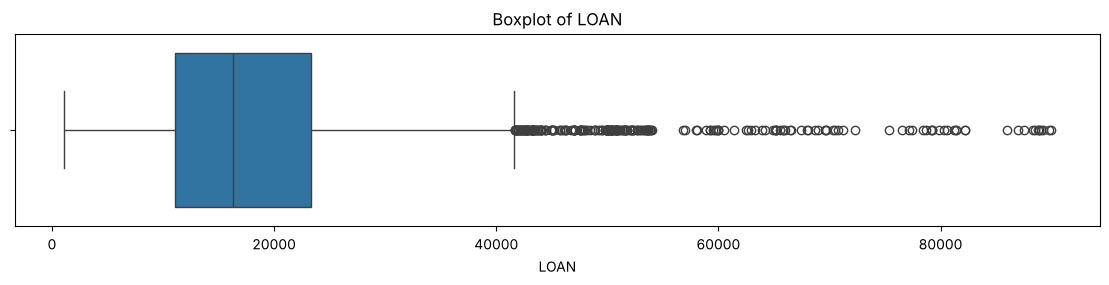

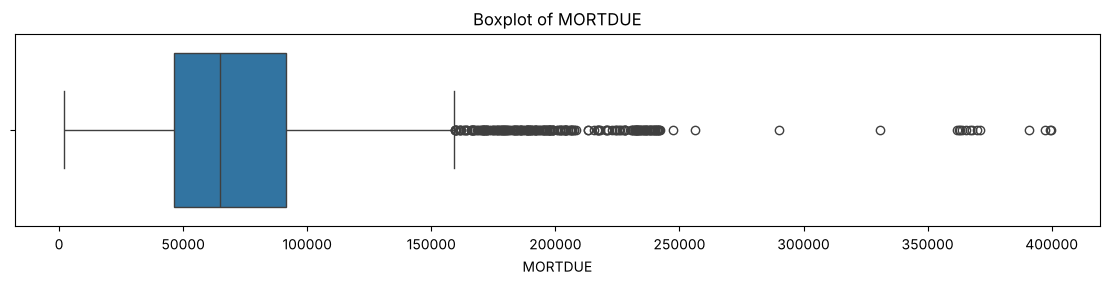

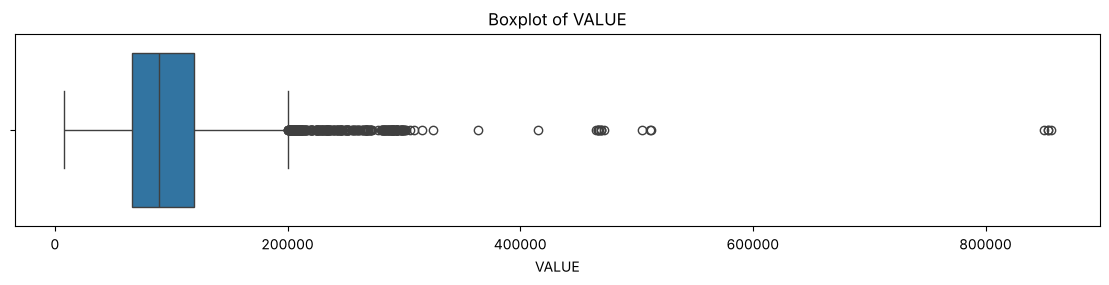

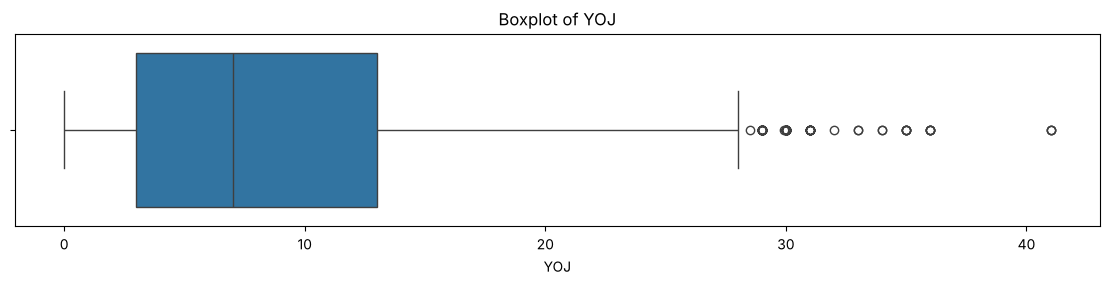

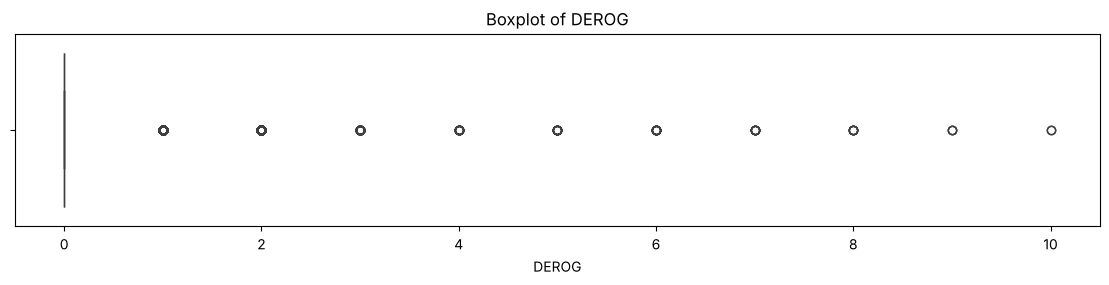

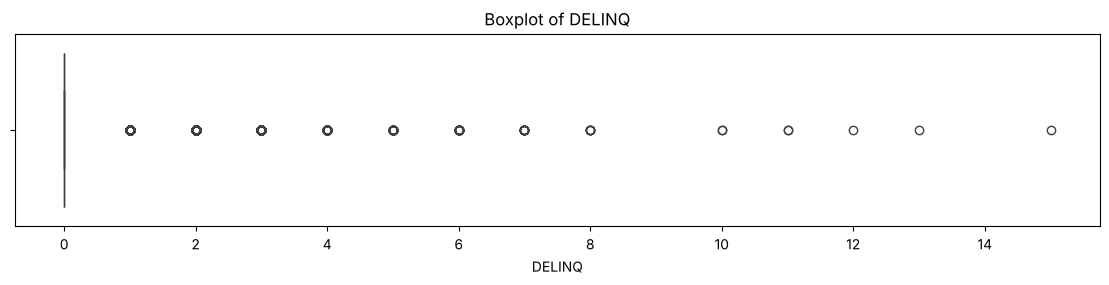

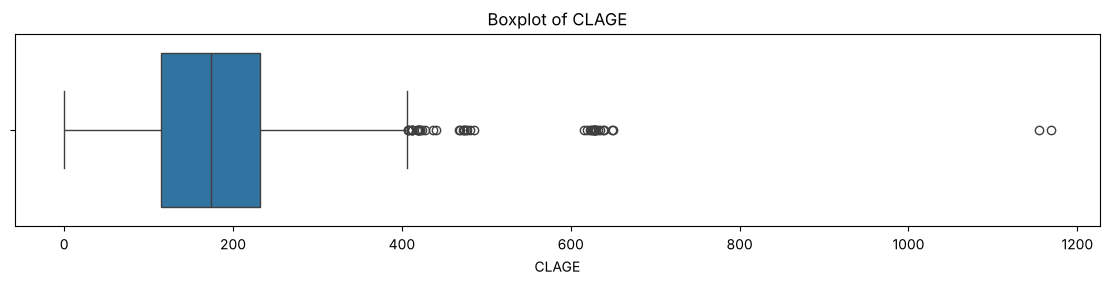

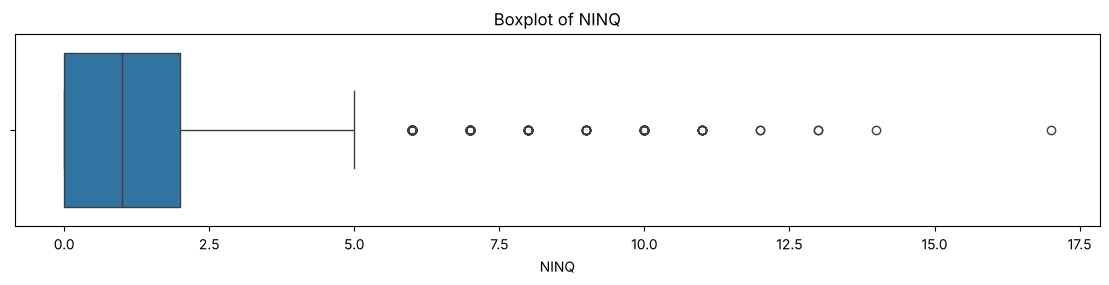

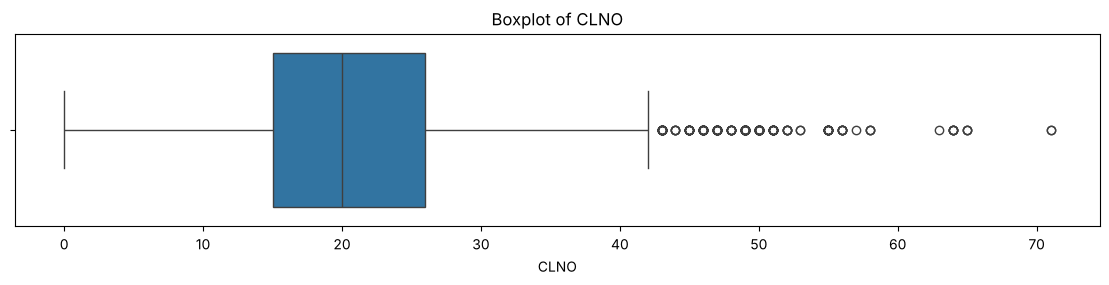

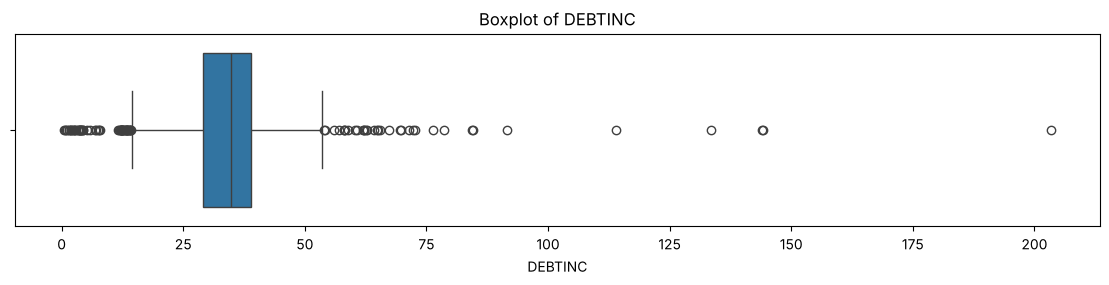

In [8]:
numeric_cols = [
    'LOAN', 'MORTDUE', 'VALUE', 'YOJ',
    'DEROG', 'DELINQ', 'CLAGE', 'NINQ',
    'CLNO', 'DEBTINC'
]

for col in numeric_cols:
    plt.figure(figsize=(14, 2.5))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [9]:
# Function to get the outliers of a column using the IQR method
def get_outlier(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    return data[(data[column] < lower_bound) | (data[column] > upper_bound)]

In [10]:
# 3-2. Outlier detection
outlier_summary = []

for col in numeric_cols:

    outliers = get_outlier(df, col)

    outlier_summary.append({
        'variable': col,
        'outliers': len(outliers),
        'percentage': len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    'outliers',
    ascending=False
)

,variable,outliers,percentage
5,DELINQ,1201,20.151007
4,DEROG,725,12.164430
2,VALUE,320,5.369128
0,LOAN,256,4.295302
1,MORTDUE,234,3.926174
8,CLNO,219,3.674497
7,NINQ,177,2.969799
9,DEBTINC,94,1.577181
3,YOJ,91,1.526846
6,CLAGE,47,0.788591


Potential outliers were identified using the IQR method with a 1.5×IQR threshold. Several variables presented a high proportion of observations outside the IQR-based boundaries, particularly DEBTINC (69.2%), CLNO (21.2%), and DELINQ (20.2%).

These observations were not automatically removed because extreme financial and credit characteristics may represent valid borrower profiles rather than data errors. Outlier treatment will therefore be based on business and domain plausibility rather than statistical thresholds alone.

## Data Understanding Conclusions

The dataset contains 5,960 observations and 13 variables related to borrower characteristics, loan information, credit history, and debt levels.

The initial analysis identified the following key characteristics:

- The target variable `BAD` is moderately imbalanced, with 80.05% of observations corresponding to non-defaulted loans and 19.95% to bad loans.
- Missing values are present in several variables, with `DEBTINC` showing the highest proportion of missing observations (21.26%).
- No duplicate records were identified.
- Several numerical variables contain statistically extreme observations according to the IQR method. These observations were not considered errors automatically, as extreme financial and credit profiles may represent valid cases.
- Variables such as `DEBTINC`, `CLAGE`, `CLNO`, and `DELINQ` show relatively wide or skewed distributions that should be considered during the exploratory analysis.
- The target variable `BAD` and the loan amount `LOAN` contain no missing values.

Overall, the dataset contains relevant financial and credit information for studying loan default risk. The next stage will focus on data cleaning, particularly the treatment of missing values and the preparation of the variables for exploratory analysis and subsequent modeling.